# German Credit Scorecard

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [55]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# Pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.4f}'.format)
# Numpy
np.set_printoptions(suppress=True, precision=4)
# Matplotlib and Seaborn
plt.rcParamsDefault['figure.figsize'] = (10, 6)
plt.rcParamsDefault['figure.dpi'] = 100
plt.rcParamsDefault['font.size'] = 11
plt.rcParamsDefault['axes.grid'] = True
plt.rcParamsDefault['grid.alpha'] = 0.3
sns.set_style('whitegrid')
sns.set_palette('muted')

SEED = 42
rng = np.random.default_rng(SEED)

In [56]:
df = pd.read_csv("../data/raw/german_credit/german.data", sep=" ", header=None)

In [57]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [58]:
columns = [
    "checking_status", "duration", "credit_history", "purpose", "credit_amount", 
    "savings_status", "employment", "installment_rate", "personal_status_sex",
    "other_parties", "residence_since", "property_magnitude", "age",
    "other_payment_plans", "housing", "existing_credits", "job",
    "num_dependents", "own_telephone", "foreign_worker", "target"
]
df.columns = columns

In [59]:
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


In [60]:
df["target"] = df["target"].map({1: 0, 2: 1})  # 1 - good, 2 - bad

In [61]:
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_rate,personal_status_sex,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,1


In [62]:
df.dtypes

checking_status          str
duration               int64
credit_history           str
purpose                  str
credit_amount          int64
savings_status           str
employment               str
installment_rate       int64
personal_status_sex      str
other_parties            str
residence_since        int64
property_magnitude       str
age                    int64
other_payment_plans      str
housing                  str
existing_credits       int64
job                      str
num_dependents         int64
own_telephone            str
foreign_worker           str
target                 int64
dtype: object

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   checking_status      1000 non-null   str  
 1   duration             1000 non-null   int64
 2   credit_history       1000 non-null   str  
 3   purpose              1000 non-null   str  
 4   credit_amount        1000 non-null   int64
 5   savings_status       1000 non-null   str  
 6   employment           1000 non-null   str  
 7   installment_rate     1000 non-null   int64
 8   personal_status_sex  1000 non-null   str  
 9   other_parties        1000 non-null   str  
 10  residence_since      1000 non-null   int64
 11  property_magnitude   1000 non-null   str  
 12  age                  1000 non-null   int64
 13  other_payment_plans  1000 non-null   str  
 14  housing              1000 non-null   str  
 15  existing_credits     1000 non-null   int64
 16  job                  1000 non-null  

In [64]:
df.isna().sum()

checking_status        0
duration               0
credit_history         0
purpose                0
credit_amount          0
savings_status         0
employment             0
installment_rate       0
personal_status_sex    0
other_parties          0
residence_since        0
property_magnitude     0
age                    0
other_payment_plans    0
housing                0
existing_credits       0
job                    0
num_dependents         0
own_telephone          0
foreign_worker         0
target                 0
dtype: int64

In [65]:
df.nunique()

checking_status          4
duration                33
credit_history           5
purpose                 10
credit_amount          921
savings_status           5
employment               5
installment_rate         4
personal_status_sex      4
other_parties            3
residence_since          4
property_magnitude       4
age                     53
other_payment_plans      3
housing                  3
existing_credits         4
job                      4
num_dependents           2
own_telephone            2
foreign_worker           2
target                   2
dtype: int64

In [66]:
df.duplicated().sum()

np.int64(0)

In [67]:
df['target'].value_counts(normalize=True)

target
0   0.7000
1   0.3000
Name: proportion, dtype: float64

In [68]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="str").columns.tolist()
numeric_cols.remove("target")
print(f"Numeric columns: {numeric_cols}")
print(f"Categorical columns: {categorical_cols}")

Numeric columns: ['duration', 'credit_amount', 'installment_rate', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical columns: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status_sex', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


In [69]:
df[numeric_cols].nunique().sort_values()

num_dependents        2
installment_rate      4
residence_since       4
existing_credits      4
duration             33
age                  53
credit_amount       921
dtype: int64

In [70]:
low_card_numeric = ["num_dependents", "installment_rate", "residence_since", "existing_credits"]
continous_numeric = [c for c in numeric_cols if c not in low_card_numeric]

### Plot:

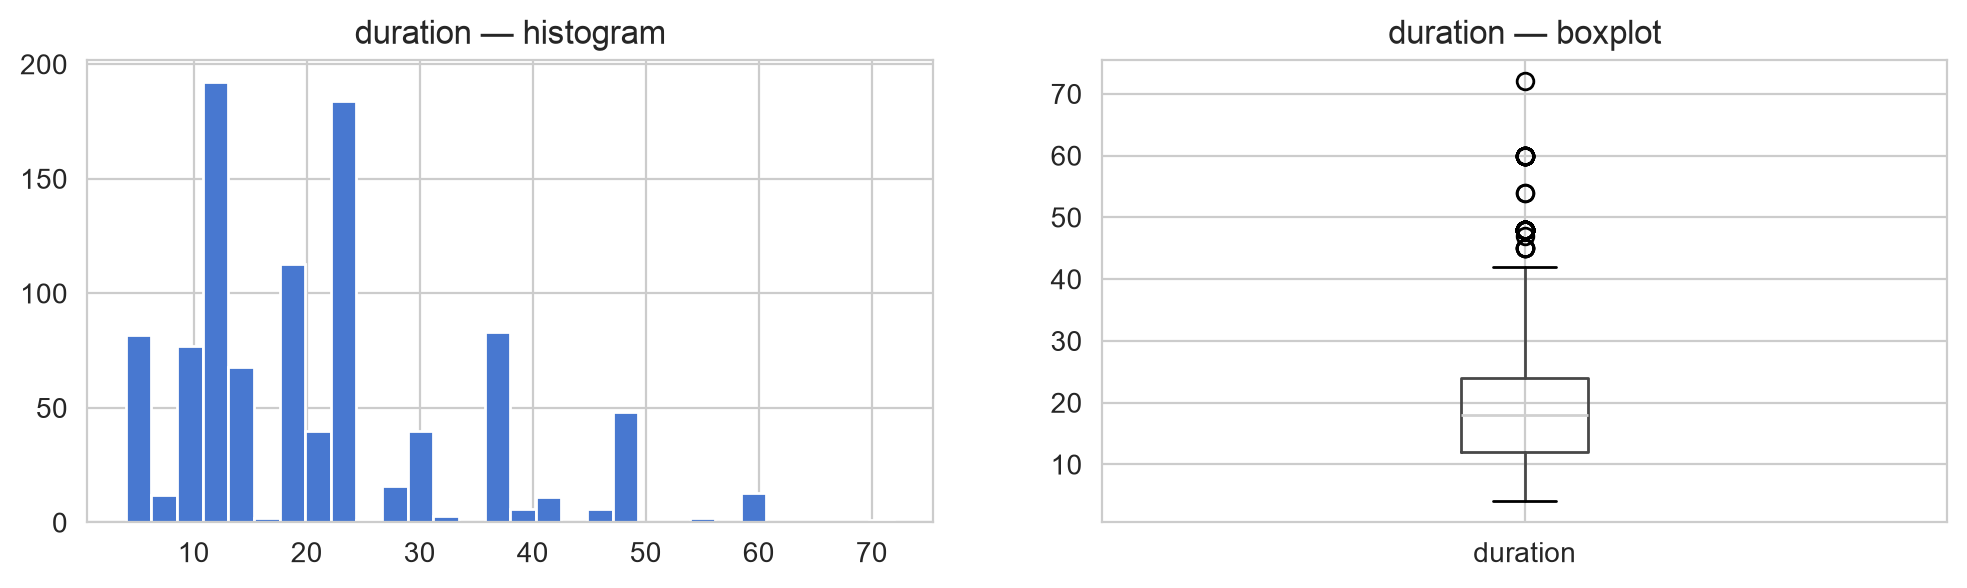

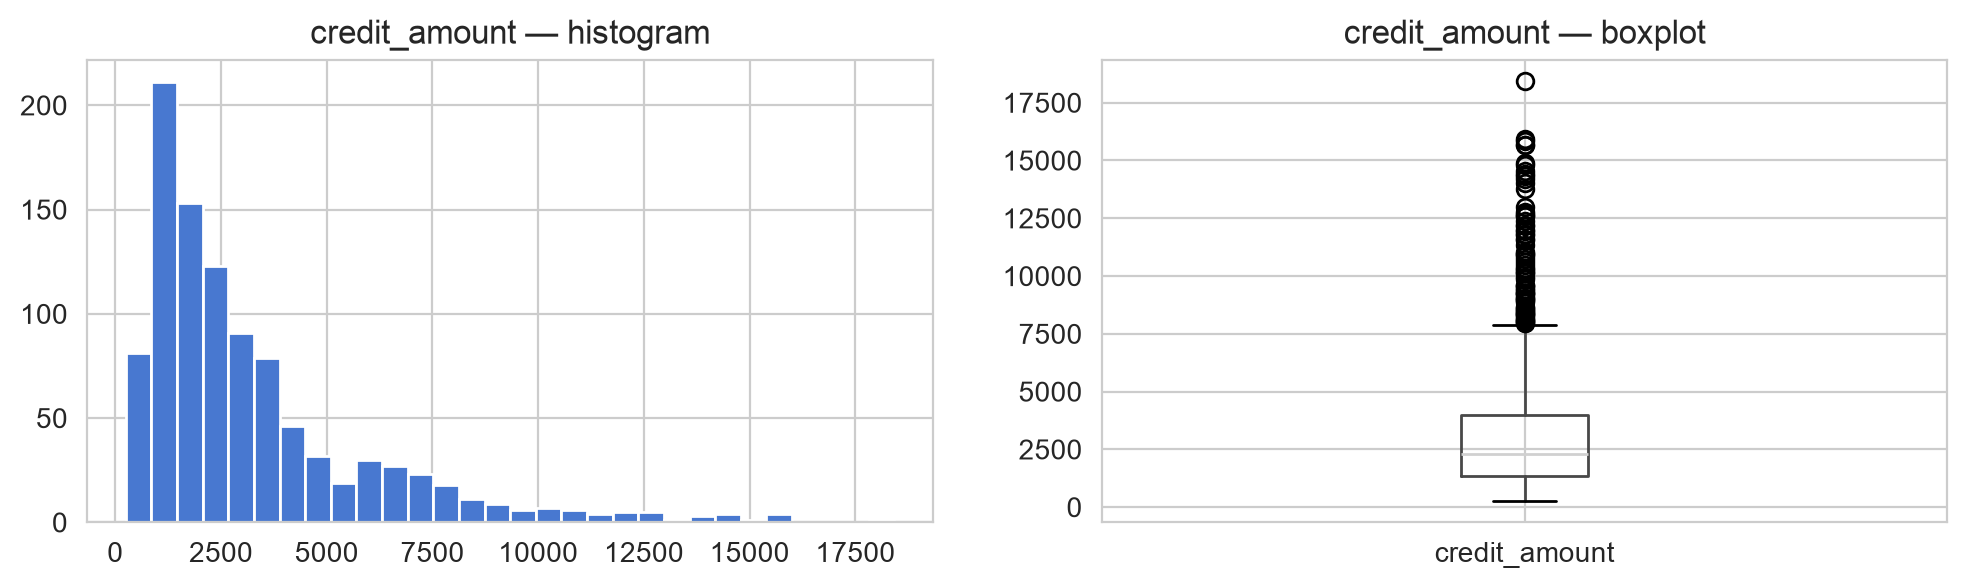

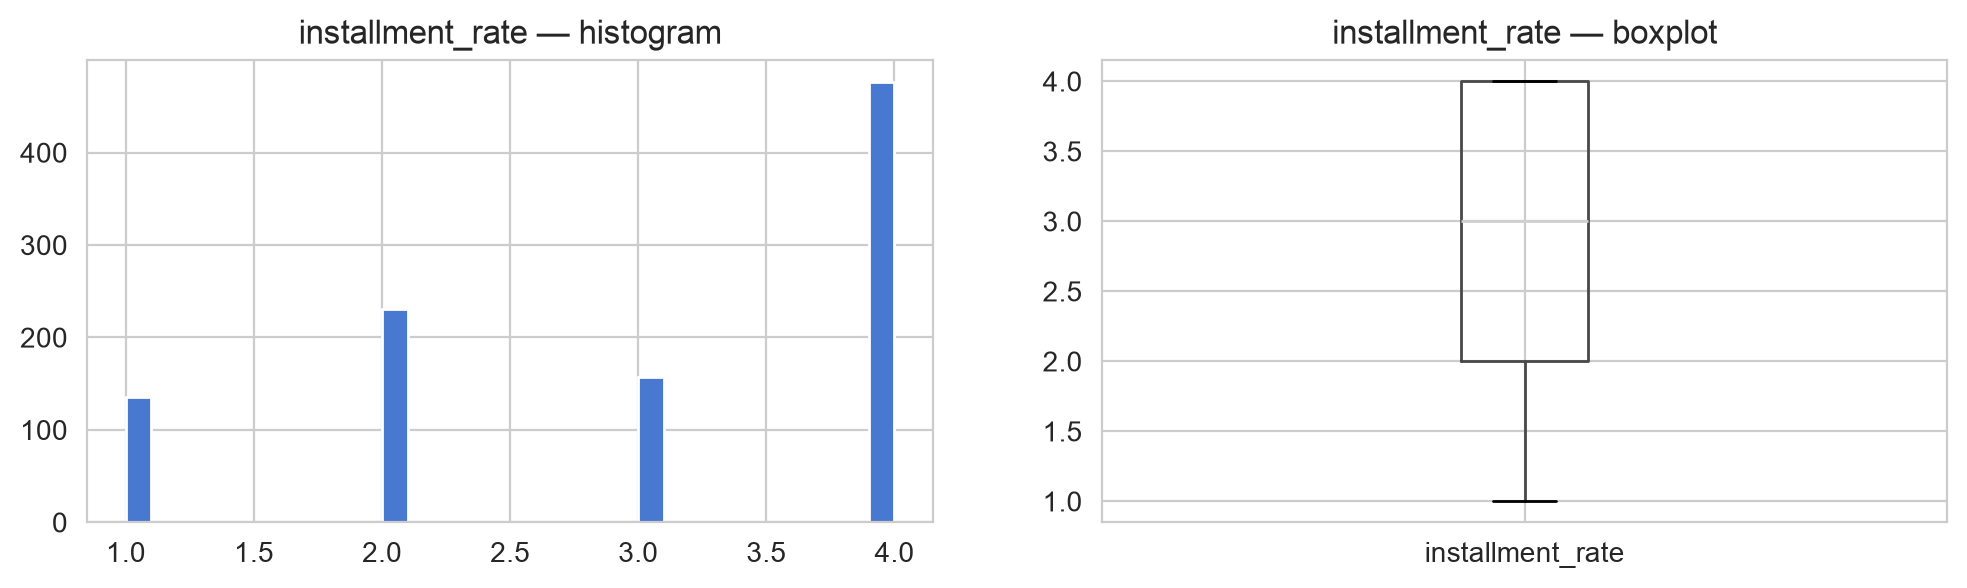

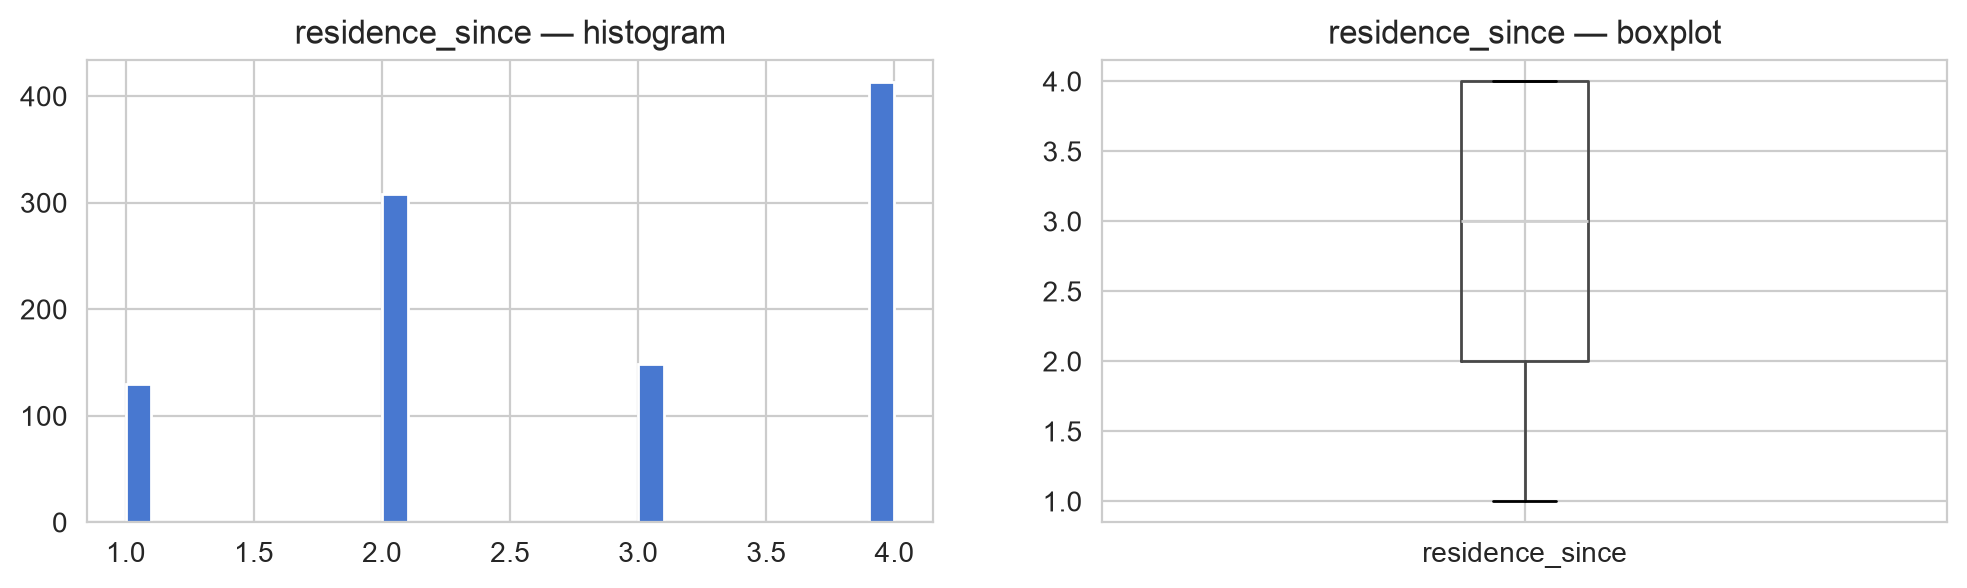

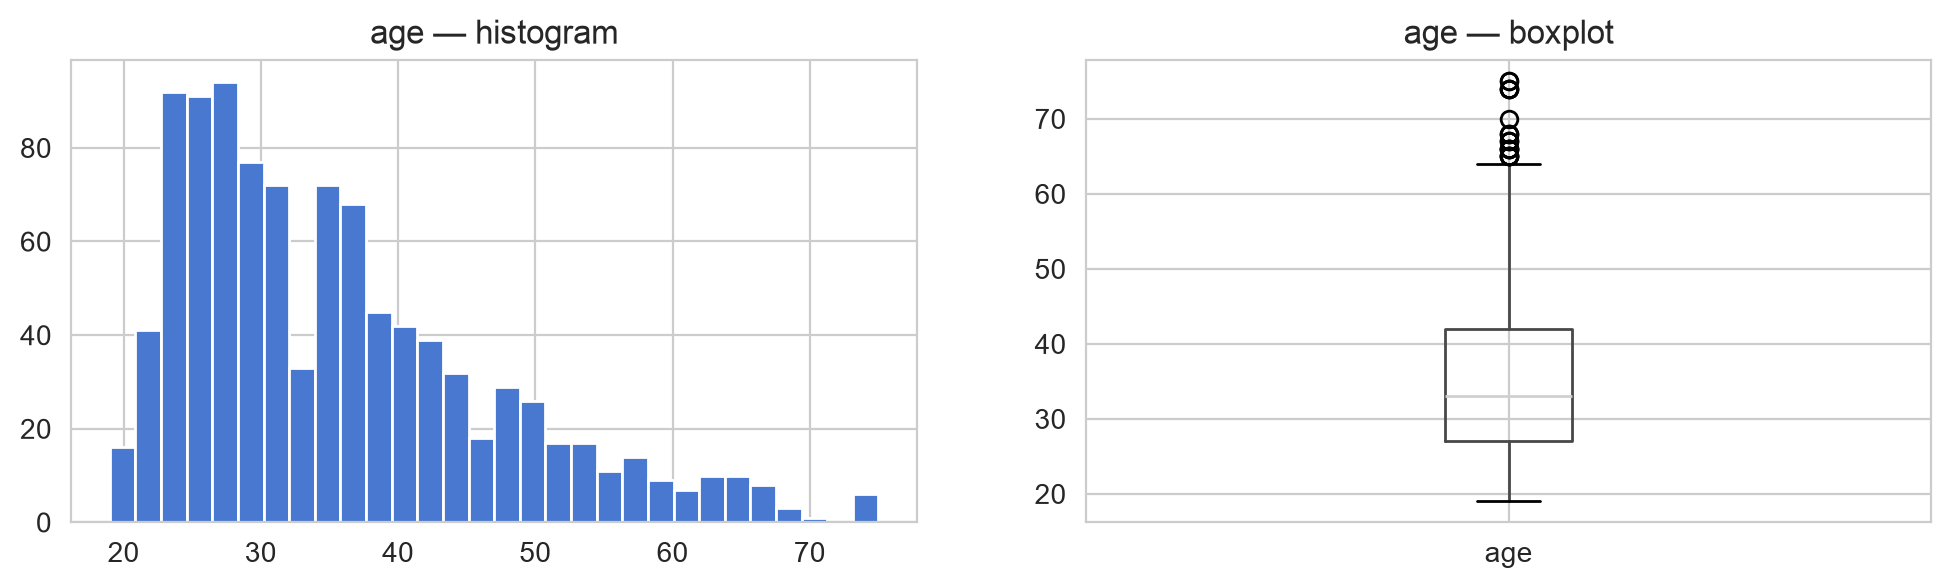

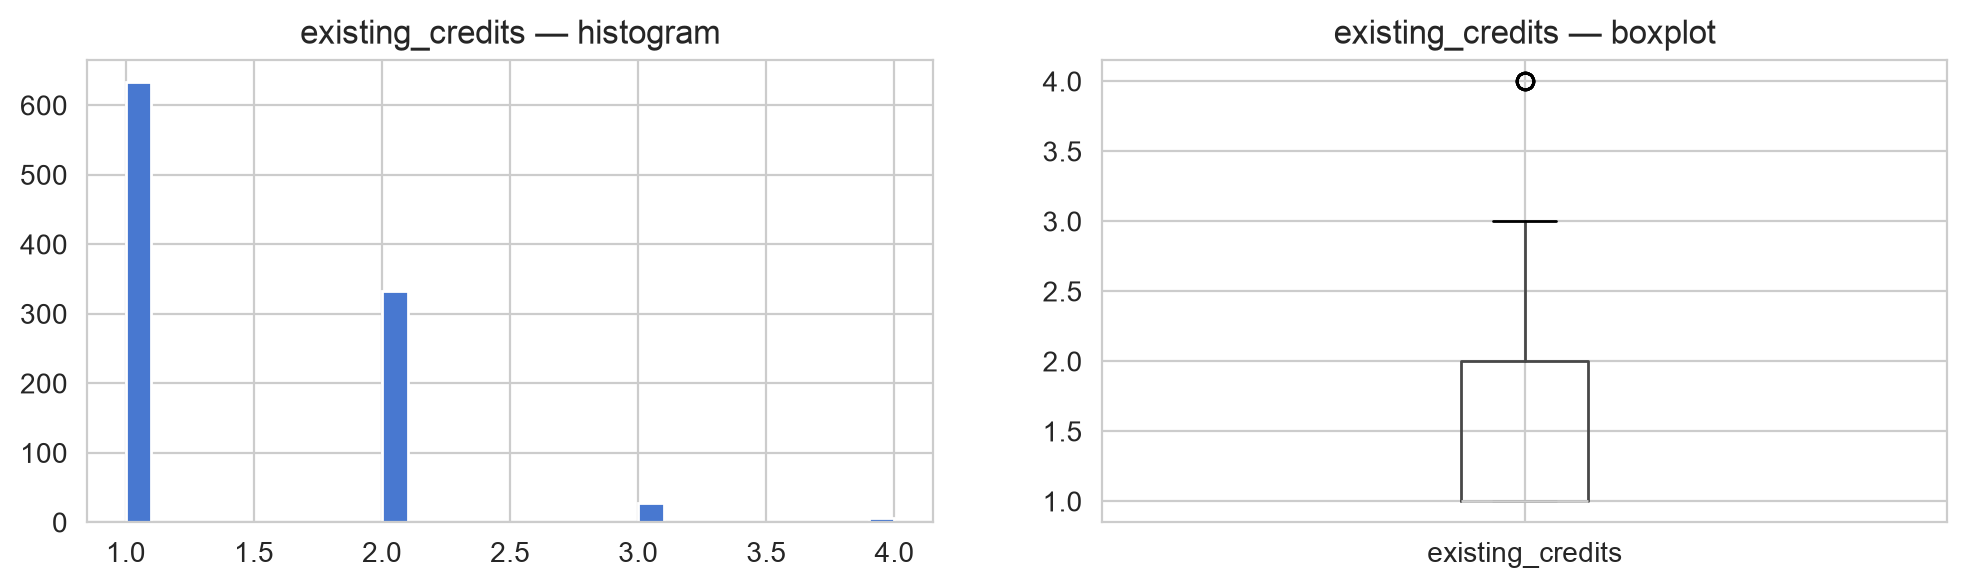

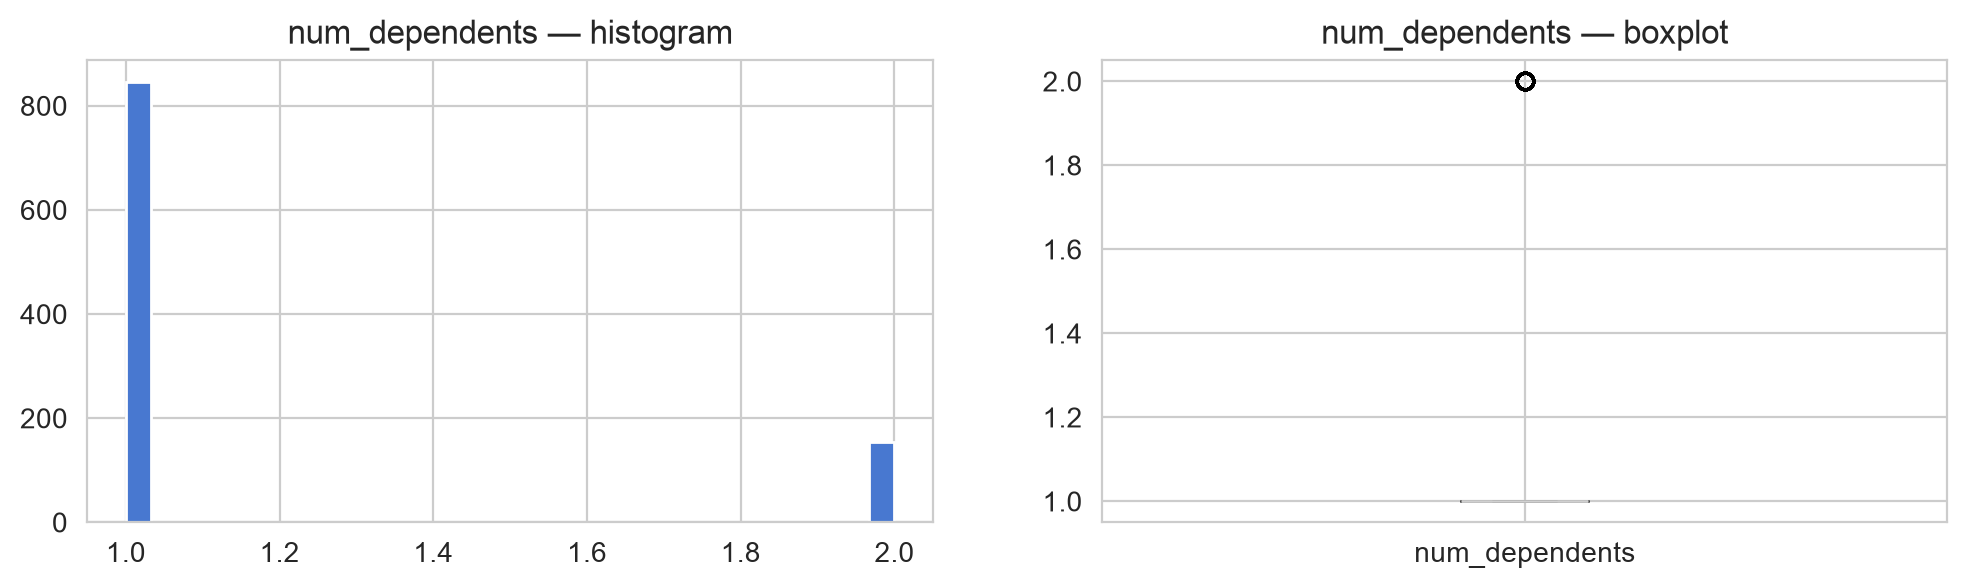

In [71]:
for col in numeric_cols:
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    df[col].hist(bins=30, ax=ax[0])
    ax[0].set_title(f"{col} — histogram")
    df.boxplot(column=col, ax=ax[1])
    ax[1].set_title(f"{col} — boxplot")
    plt.show()

checking_status
A14    394
A11    274
A12    269
A13     63
Name: count, dtype: int64



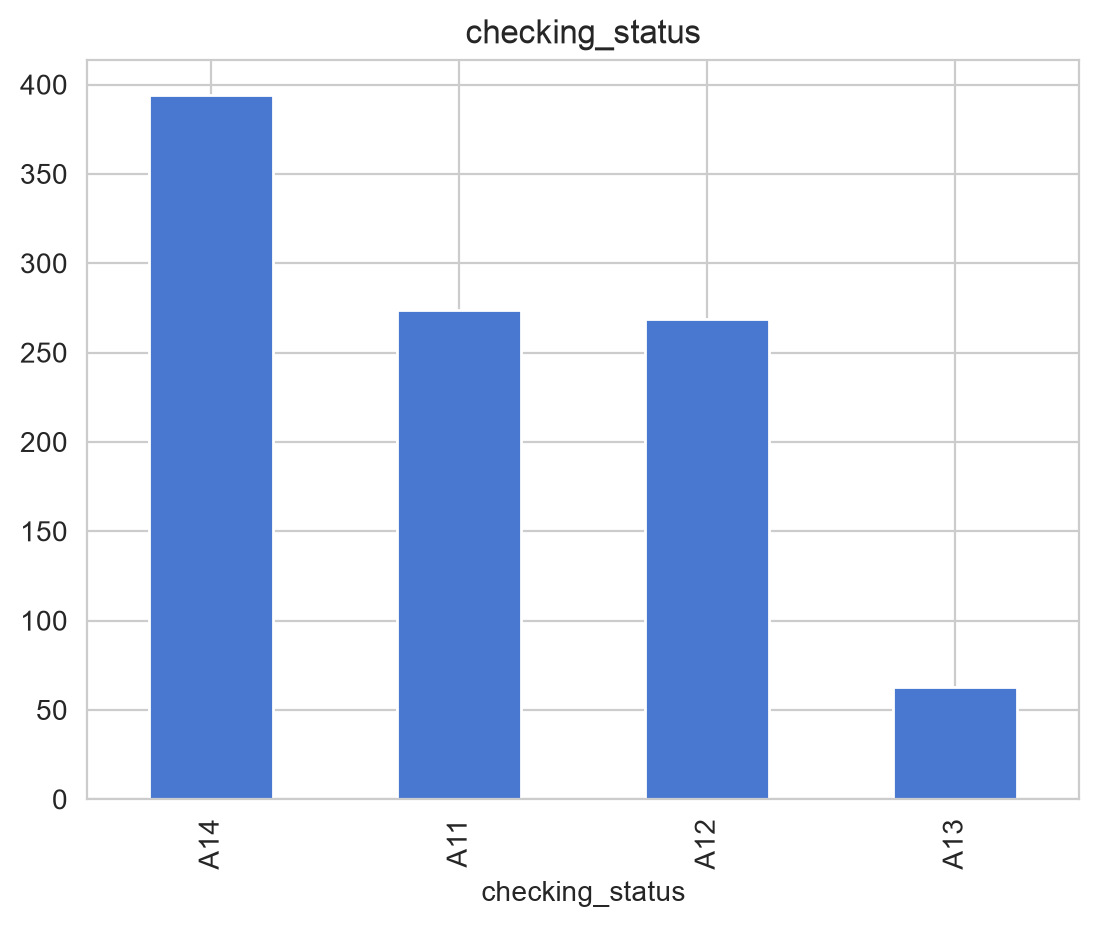

credit_history
A32    530
A34    293
A33     88
A31     49
A30     40
Name: count, dtype: int64



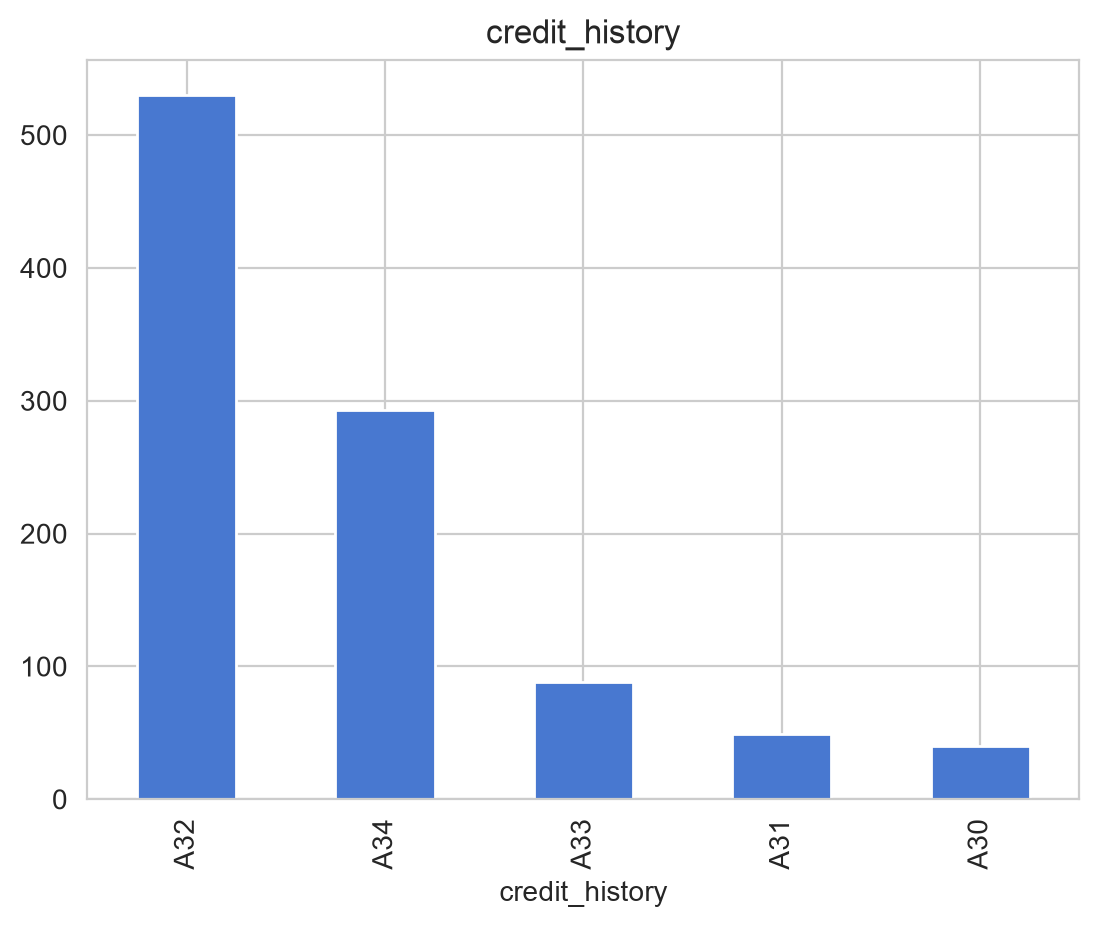

purpose
A43     280
A40     234
A42     181
A41     103
A49      97
A46      50
A45      22
A44      12
A410     12
A48       9
Name: count, dtype: int64



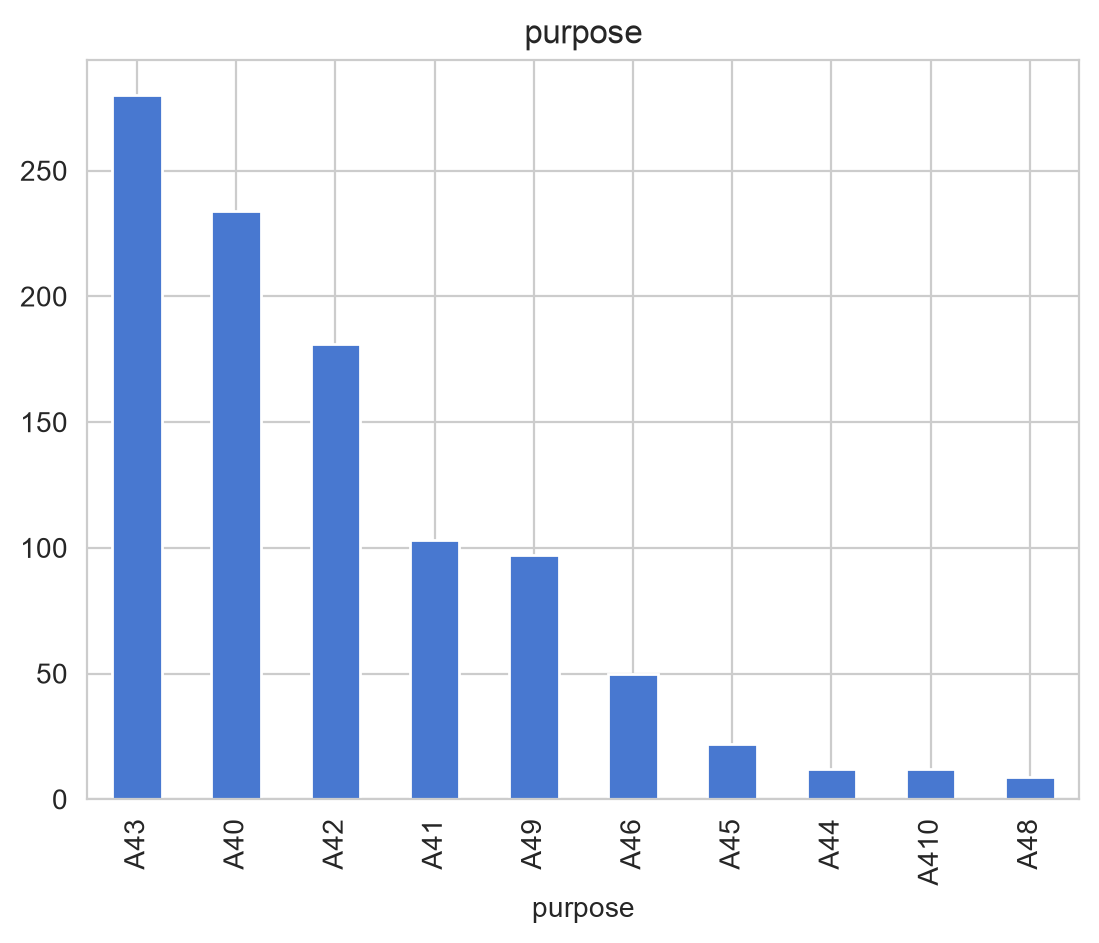

savings_status
A61    603
A65    183
A62    103
A63     63
A64     48
Name: count, dtype: int64



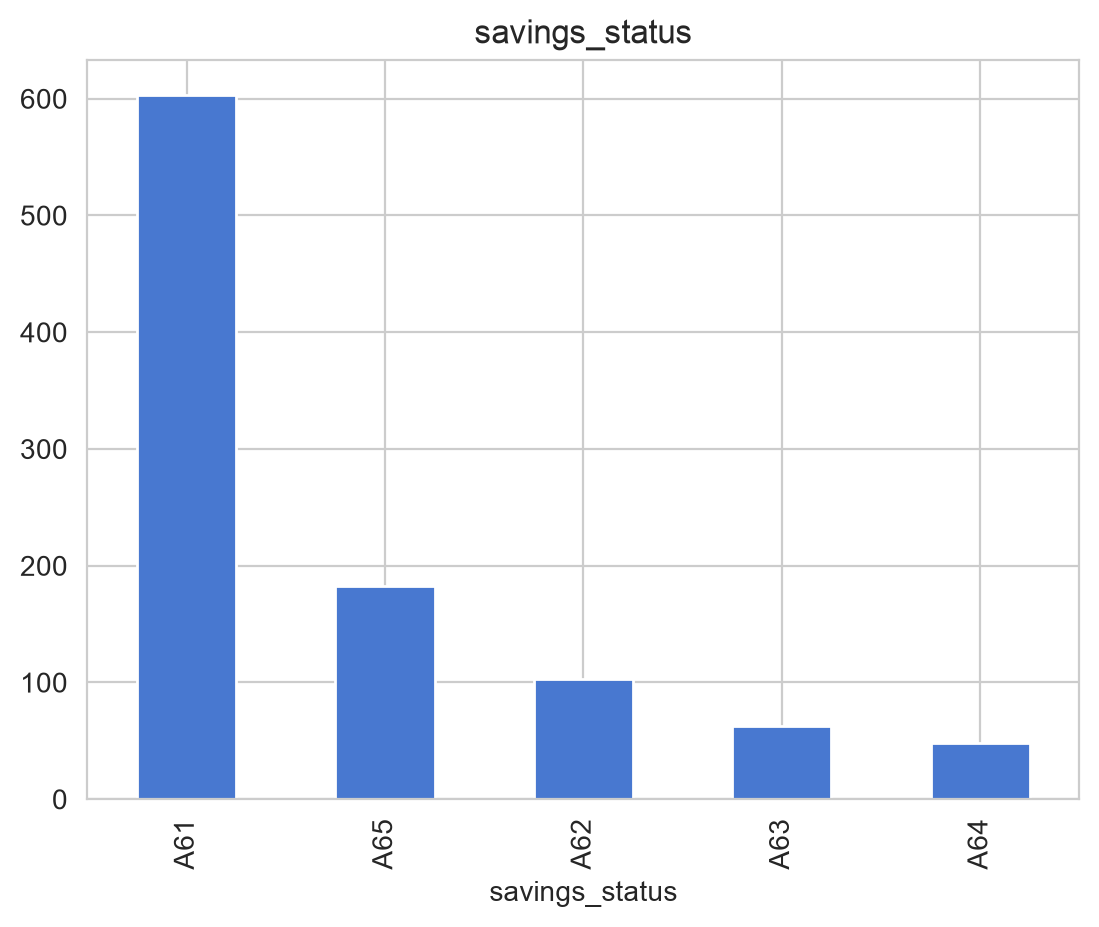

employment
A73    339
A75    253
A74    174
A72    172
A71     62
Name: count, dtype: int64



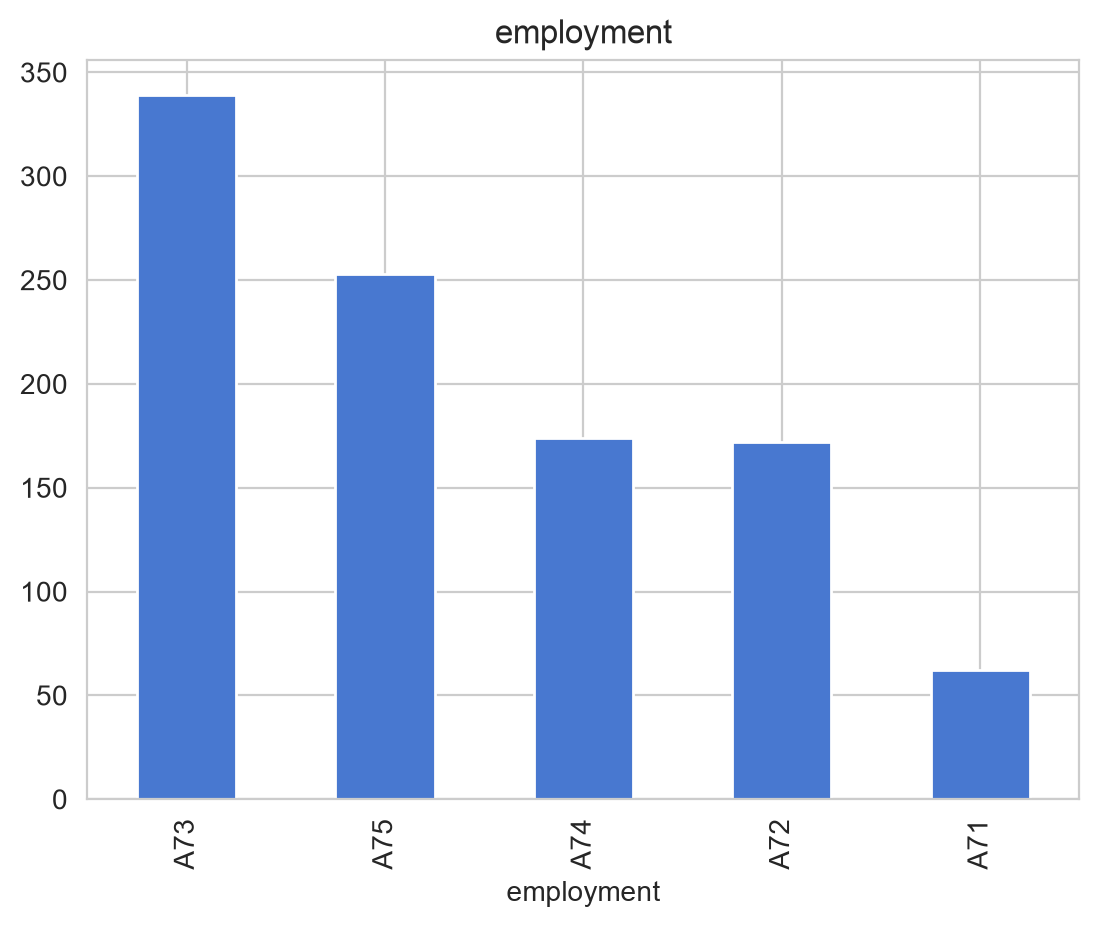

personal_status_sex
A93    548
A92    310
A94     92
A91     50
Name: count, dtype: int64



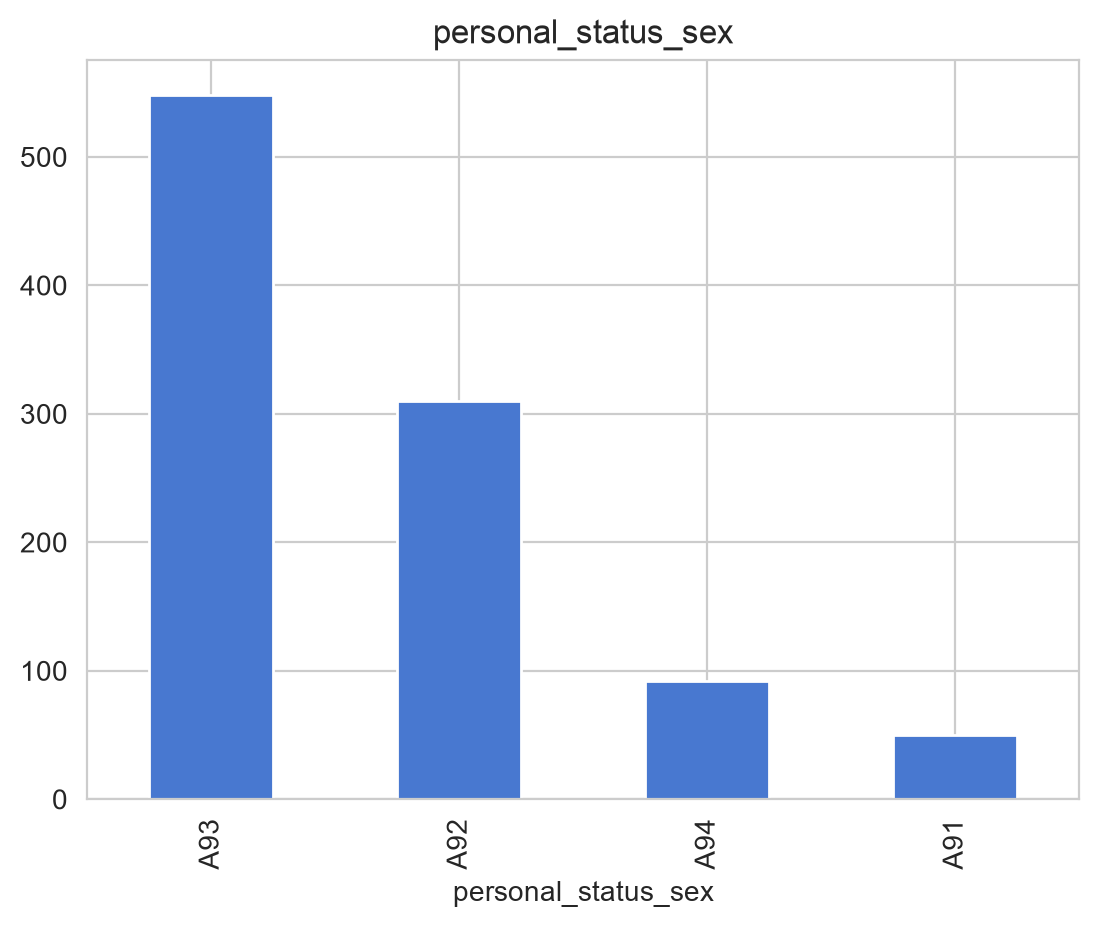

other_parties
A101    907
A103     52
A102     41
Name: count, dtype: int64



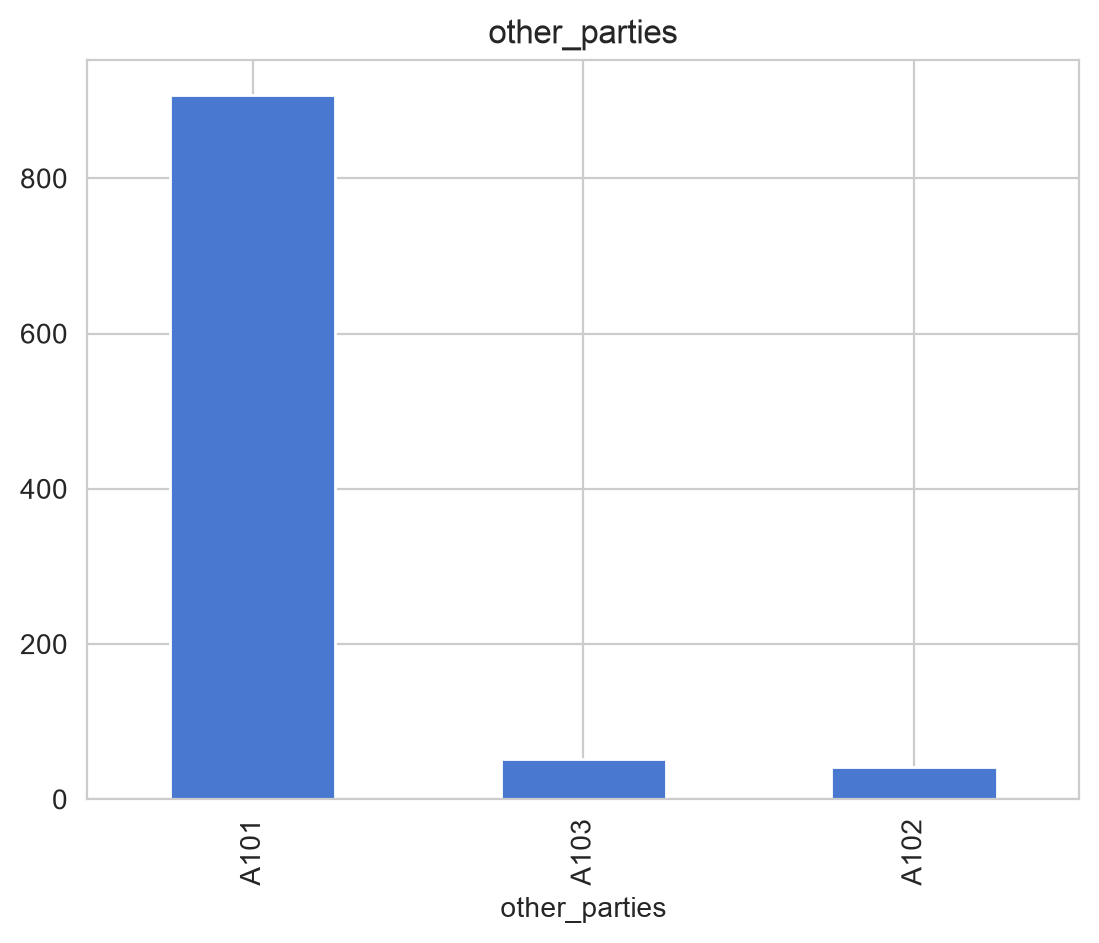

property_magnitude
A123    332
A121    282
A122    232
A124    154
Name: count, dtype: int64



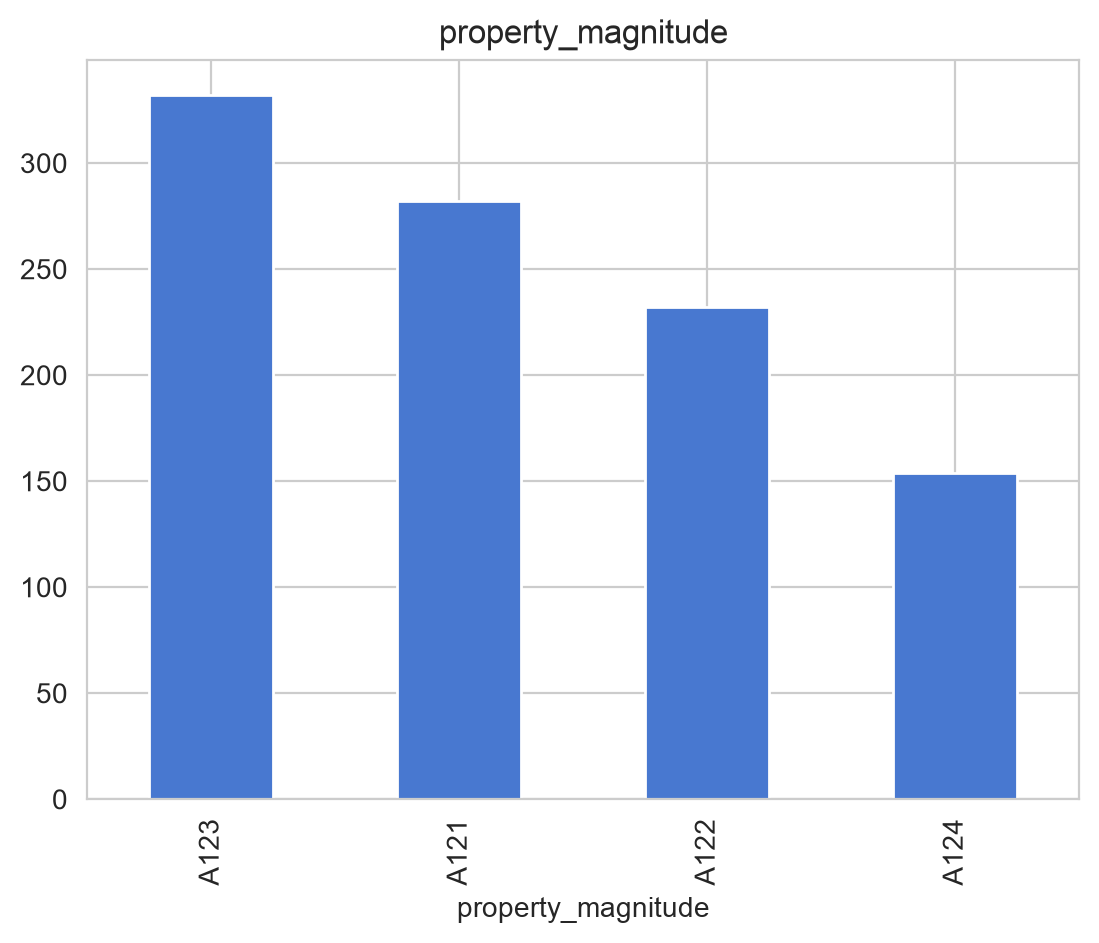

other_payment_plans
A143    814
A141    139
A142     47
Name: count, dtype: int64



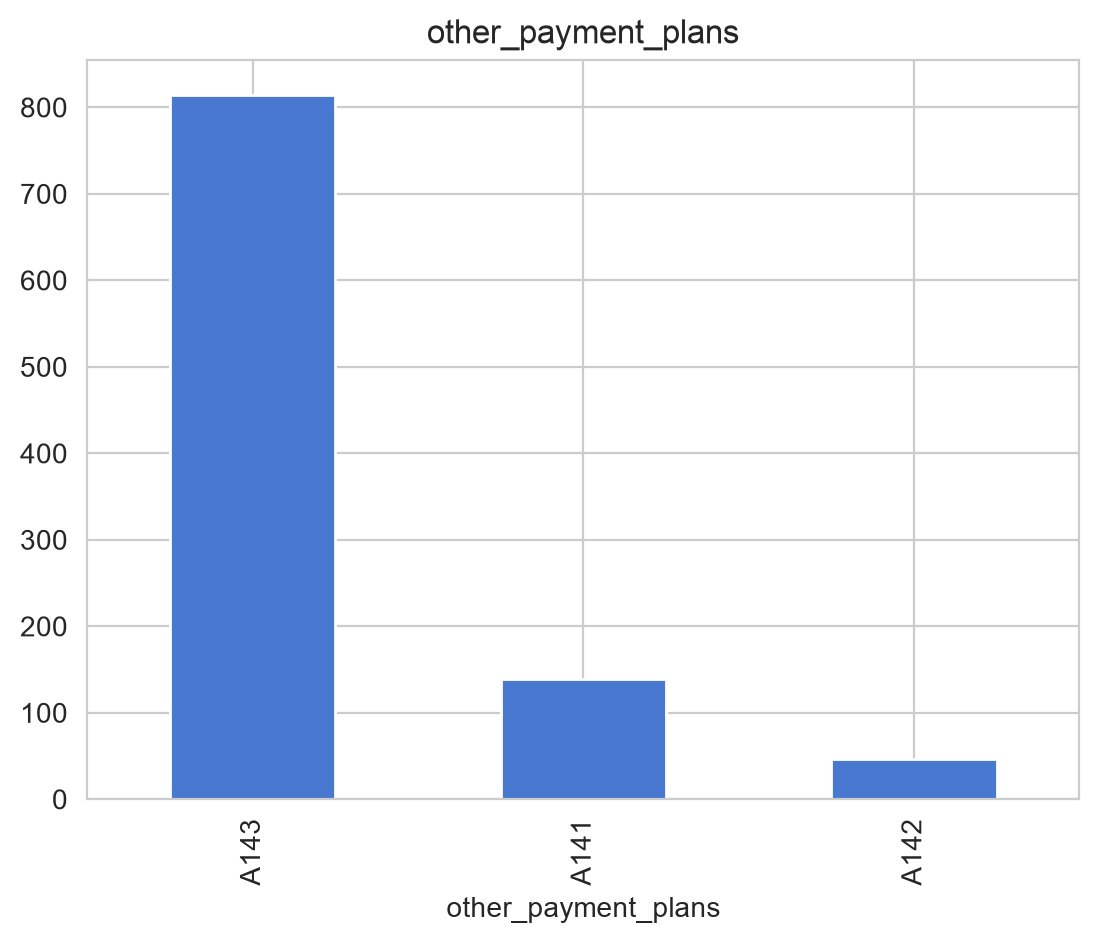

housing
A152    713
A151    179
A153    108
Name: count, dtype: int64



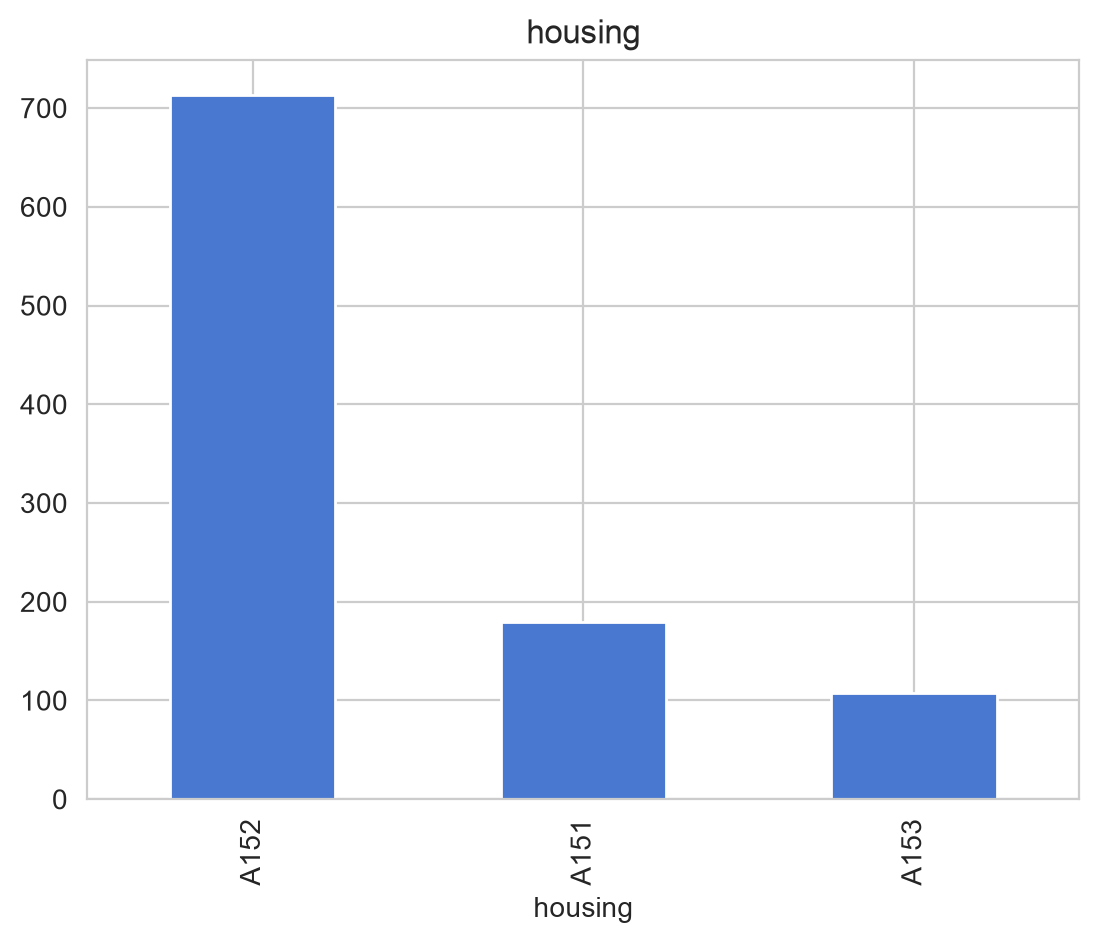

job
A173    630
A172    200
A174    148
A171     22
Name: count, dtype: int64



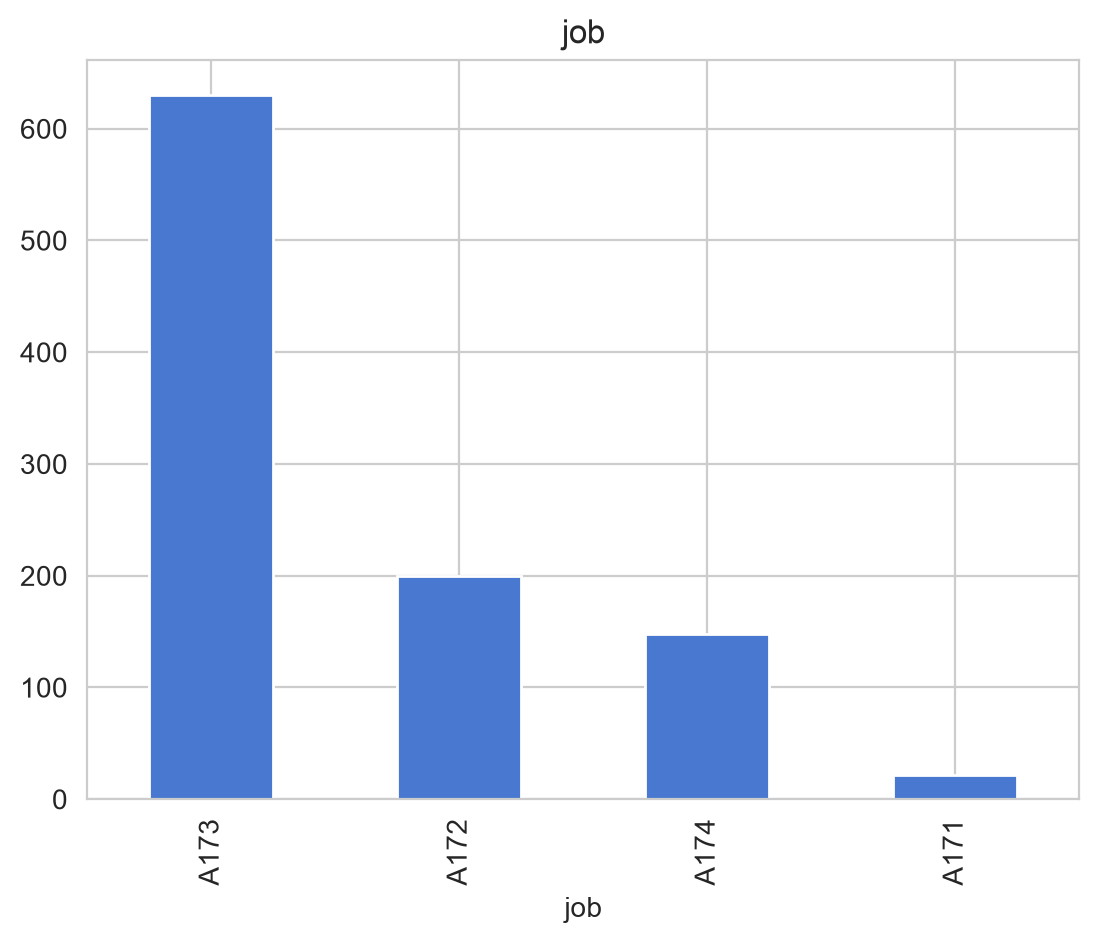

own_telephone
A191    596
A192    404
Name: count, dtype: int64



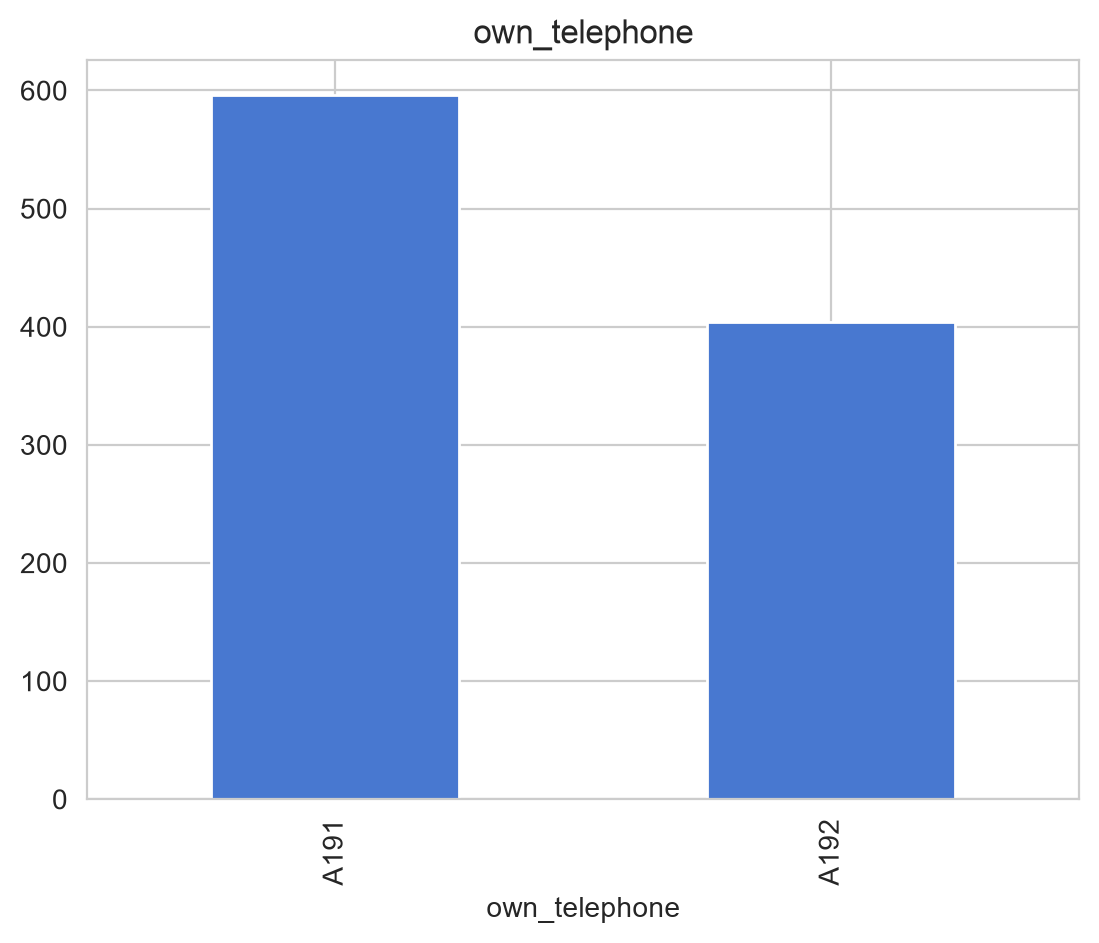

foreign_worker
A201    963
A202     37
Name: count, dtype: int64



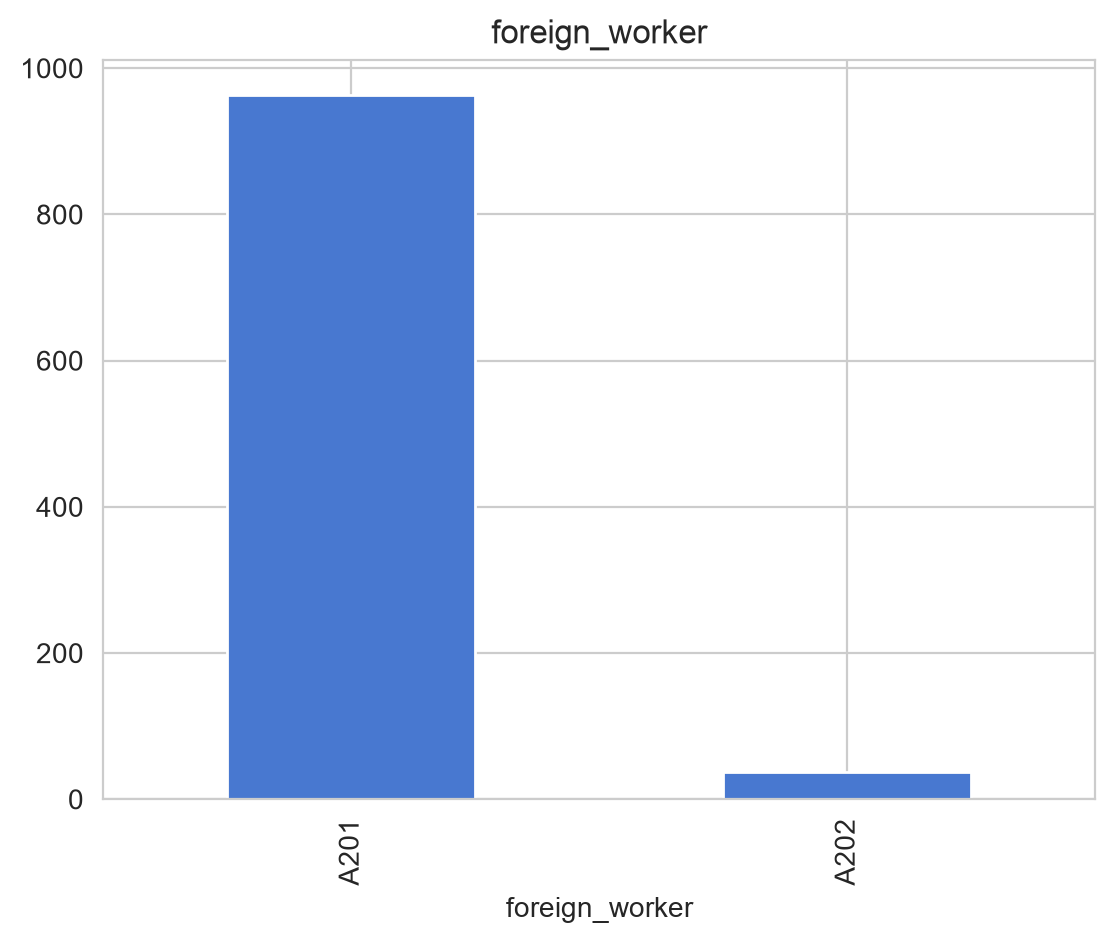

In [72]:
for col in categorical_cols:
    print(df[col].value_counts())
    print()
    df[col].value_counts().plot(kind="bar", title=col)
    plt.show()

In [73]:
for col in categorical_cols:
    rates = df.groupby(col)["target"].agg(["mean", "count"])
    rates.columns = ["default_rate", "count"]
    print(f"\n--- {col} ---")
    print(rates.sort_values("default_rate"))


--- checking_status ---
                 default_rate  count
checking_status                     
A14                    0.1168    394
A13                    0.2222     63
A12                    0.3903    269
A11                    0.4927    274

--- credit_history ---
                default_rate  count
credit_history                     
A34                   0.1706    293
A33                   0.3182     88
A32                   0.3189    530
A31                   0.5714     49
A30                   0.6250     40

--- purpose ---
         default_rate  count
purpose                     
A48            0.1111      9
A41            0.1650    103
A43            0.2214    280
A42            0.3204    181
A44            0.3333     12
A49            0.3505     97
A45            0.3636     22
A40            0.3803    234
A410           0.4167     12
A46            0.4400     50

--- savings_status ---
                default_rate  count
savings_status                     
A64             

In [74]:
for col in continous_numeric:
    df[f"{col}_qbin"] = pd.qcut(df[col], q=5, duplicates="drop")
    print(df.groupby(f"{col}_qbin")["target"].mean())
    df.drop(columns=f"{col}_qbin", inplace=True)

duration_qbin
(3.999, 12.0]   0.2117
(12.0, 15.0]    0.1806
(15.0, 24.0]    0.3215
(24.0, 30.0]    0.3333
(30.0, 72.0]    0.4798
Name: target, dtype: float64
credit_amount_qbin
(249.999, 1262.0]   0.3035
(1262.0, 1906.8]    0.2412
(1906.8, 2852.4]    0.2700
(2852.4, 4720.0]    0.2600
(4720.0, 18424.0]   0.4250
Name: target, dtype: float64
age_qbin
(18.999, 26.0]   0.3917
(26.0, 30.0]     0.3158
(30.0, 36.0]     0.2593
(36.0, 45.0]     0.2620
(45.0, 75.0]     0.2527
Name: target, dtype: float64


**choose 5 features:** *checking_status, duration, savings_status, age, credit_history*

categorical: 
- checking_status
- savings_status
- credit_history

numerical:
- duration
- age

Train/test split

In [75]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(800, 20) (200, 20)
0.3 0.3


In [76]:
print(X_train["checking_status"].value_counts())
print(X_train["credit_history"].value_counts())
print(X_train["savings_status"].value_counts())

checking_status
A14    316
A11    219
A12    214
A13     51
Name: count, dtype: int64
credit_history
A32    416
A34    240
A33     72
A31     41
A30     31
Name: count, dtype: int64
savings_status
A61    475
A65    144
A62     90
A63     50
A64     41
Name: count, dtype: int64


In [77]:
categorical_binned = ["checking_status", "savings_status", "credit_history"]

In [78]:
X_train["duration"].value_counts().sort_index()

duration
4       5
6      59
7       4
8       6
9      43
10     21
11      6
12    144
13      2
14      4
15     54
16      1
18     88
20      7
21     23
22      2
24    149
26      1
27      8
28      3
30     32
33      3
36     70
39      4
40      1
42     10
45      2
47      1
48     36
54      1
60     10
Name: count, dtype: int64

In [79]:
X_train["duration_bin"], duration_edges = pd.qcut(
    X_train["duration"], q=5, retbins=True, duplicates="drop"
)
X_train["duration_bin"].value_counts()  # confirm bins are reasonably populated

duration_bin
(3.999, 12.0]    288
(15.0, 24.0]     270
(30.0, 60.0]     138
(12.0, 15.0]      60
(24.0, 30.0]      44
Name: count, dtype: int64

In [80]:
X_train["age_bin"], age_edges = pd.qcut(
    X_train["age"], q=5, retbins=True, duplicates="drop"
)
X_train["age_bin"].value_counts()

age_bin
(18.999, 26.0]    185
(30.0, 36.0]      183
(44.0, 75.0]      153
(26.0, 30.0]      143
(36.0, 44.0]      136
Name: count, dtype: int64

In [81]:
bin_artifacts = {
    "duration": duration_edges,
    "age": age_edges,
}

In [82]:
binned_features = ["checking_status", "savings_status", "credit_history", "duration_bin", "age_bin"]

for col in binned_features:
    print(f"\n--- {col} ---")
    print(pd.DataFrame({col: X_train[col], "target": y_train}).groupby(col)["target"].agg(["mean", "count"]))


--- checking_status ---
                  mean  count
checking_status              
A11             0.4795    219
A12             0.3925    214
A13             0.2549     51
A14             0.1203    316

--- savings_status ---
                 mean  count
savings_status              
A61            0.3642    475
A62            0.3333     90
A63            0.1600     50
A64            0.1220     41
A65            0.1667    144

--- credit_history ---
                 mean  count
credit_history              
A30            0.6129     31
A31            0.5366     41
A32            0.3221    416
A33            0.3194     72
A34            0.1750    240

--- duration_bin ---
                mean  count
duration_bin               
(3.999, 12.0] 0.2049    288
(12.0, 15.0]  0.1833     60
(15.0, 24.0]  0.3407    270
(24.0, 30.0]  0.3182     44
(30.0, 60.0]  0.4638    138

--- age_bin ---
                 mean  count
age_bin                     
(18.999, 26.0] 0.3784    185
(26.0, 30.0]   0.30

### WOE IV

In [83]:
def compute_woe_iv(df_binned_col, target):
    grouped = pd.DataFrame({"bin": df_binned_col, "target": target})
    summary = grouped.groupby("bin")["target"].agg(["count", "sum"])
    summary.columns = ["total", "bad"]
    summary["good"] = summary["total"] - summary["bad"]

    total_good = summary["good"].sum()
    total_bad = summary["bad"].sum()

    summary["pct_good"] = (summary["good"] + 0.5) / (total_good + 0.5)
    summary["pct_bad"] = (summary["bad"] + 0.5) / (total_bad + 0.5)

    summary["woe"] = np.log(summary["pct_good"] / summary["pct_bad"])
    summary["iv_contribution"] = (summary["pct_good"] - summary["pct_bad"]) * summary["woe"]

    total_iv = summary["iv_contribution"].sum()
    return summary, total_iv

In [84]:

iv_results = {}
woe_tables = {}

for col in binned_features:
    summary, iv = compute_woe_iv(X_train[col], y_train)
    woe_tables[col] = summary
    iv_results[col] = iv

pd.Series(iv_results).sort_values(ascending=False)

checking_status   0.6119
credit_history    0.2640
savings_status    0.2154
duration_bin      0.2145
age_bin           0.0432
dtype: float64

### Step 12 apply same bins/woe mappings to X_test

In [85]:
# categorical — direct WOE lookup, same mapping learned from train
for col in ["checking_status", "savings_status", "credit_history"]:
    woe_map = woe_tables[col]["woe"].to_dict()
    X_test[f"{col}_woe"] = X_test[col].map(woe_map)

In [86]:
X_test["duration_bin"] = pd.cut(X_test["duration"], bins=duration_edges, include_lowest=True)
X_test["age_bin"] = pd.cut(X_test["age"], bins=age_edges, include_lowest=True)

X_test["duration_bin_woe"] = X_test["duration_bin"].map(woe_tables["duration_bin"]["woe"].to_dict())
X_test["age_bin_woe"] = X_test["age_bin"].map(woe_tables["age_bin"]["woe"].to_dict())

In [87]:
woe_cols = ["checking_status", "savings_status", "credit_history", "duration_bin_woe", "age_bin_woe"]

# for the categorical ones, the mapped column names would be like "checking_status_woe" etc.
# adjust names to match whatever you actually assigned
X_test[["checking_status_woe", "savings_status_woe", "credit_history_woe", 
        "duration_bin_woe", "age_bin_woe"]].isna().sum()

checking_status_woe    0
savings_status_woe     0
credit_history_woe     0
duration_bin_woe       1
age_bin_woe            0
dtype: int64

In [88]:
# find the actual row(s) with the NaN
print(X_test[X_test["duration_bin_woe"].isna()][["duration", "duration_bin"]])

     duration duration_bin
677        72          NaN


In [89]:
# 1. Extend the edges once, right after you got them from qcut
duration_edges_extended = duration_edges.copy()
duration_edges_extended[0] = -np.inf
duration_edges_extended[-1] = np.inf

# 2. Re-cut X_train using the EXTENDED edges (overwrite the original duration_bin)
X_train["duration_bin"] = pd.cut(X_train["duration"], bins=duration_edges_extended, include_lowest=True)

# 3. Recompute WOE/IV on this re-cut column
woe_tables["duration_bin"], iv_results["duration_bin"] = compute_woe_iv(X_train["duration_bin"], y_train)

# 4. Now cut X_test with the SAME extended edges — bins will match exactly
X_test["duration_bin"] = pd.cut(X_test["duration"], bins=duration_edges_extended, include_lowest=True)
X_test["duration_bin_woe"] = X_test["duration_bin"].map(woe_tables["duration_bin"]["woe"].to_dict())

X_test["duration_bin_woe"].isna().sum()  # should be 0 now

np.int64(0)

### Fit the model

In [ ]:
woe_feature_cols = ["checking_status_woe", "savings_status_woe", "credit_history_woe", 
                     "duration_bin_woe", "age_bin_woe"]

X_train_woe = X_train[woe_feature_cols]
X_test_woe = X_test[woe_feature_cols]

model = LogisticRegression(random_state=SEED)
model.fit(X_train_woe, y_train)

KeyError: "None of [Index(['checking_status_woe', 'savings_status_woe', 'credit_history_woe',\n       'duration_bin_woe', 'age_bin_woe'],\n      dtype='str')] are in the [columns]"

### Evaluate

In [91]:
p_test = model.predict_proba(X_test_woe)[:, 1]
auc = roc_auc_score(y_test, p_test)
gini = 2 * auc - 1
print(f"AUC: {auc:.4f}, Gini: {gini:.4f}")

NameError: name 'model' is not defined

### Sanity-check coefficients